<a href="https://colab.research.google.com/github/ChronosXV/Aprendinzaje_por_Refuerzo/blob/TrabajoPractico_N2/20262C_UGR_AR_TP2_MartinezGisela.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prof. Guadalupe Pascal

Prof. Julián E. Tornillo

-----------------------------------------------
# Diferencia Temporal con OpenAI Gym





##Introducción:

### Resumen

Los algoritmos de Aprendizaje por Refuerzo (RL) buscan aprender a tomar decisiones secuenciales en entornos desconocidos. Para lograr esto, los algoritmos de Diferencia Temporal (TD) incorporan conceptos clave de dos enfoques previos:

### Programación Dinámica

La Programación Dinámica se centra en resolver problemas de **optimización** a través de la descomposición en subproblemas más pequeños. Los elementos del proceso de decisión de Markov (MDP) son conocidos, por lo que son basados en modelos (model-based).

La ecuación de Bellman es fundamental y se usa para calcular los valores óptimos de los estados y acciones. En el Aprendizaje por Refuerzo, los algoritmos de TD utilizan una versión de la ecuación de Bellman para actualizar los valores de estado-acción.

### Métodos Monte Carlo

Los métodos Monte Carlo se basan en la idea de estimar los valores de estado-acción a partir de la observación de episodios completos. Es posible que no se conozcan todos los elementos de los MDP, por lo que son libres de modelos (model-free).

En Aprendizaje por Refuerzo, los métodos Monte Carlo proporcionan **estimaciones** precisas de los valores, pero a menudo requieren episodios completos, lo que puede ser costoso en términos computacionales.

### Algoritmos de Diferencia Temporal (TD)

Los algoritmos de Diferencia Temporal (TD) combinan ambos enfoques. Se utiliza la ecuación de Bellman para actualizar los valores de estado-acción en función de recompensas parciales a lo largo de una secuencia de tiempo. Esto permite una estimación más rápida y eficiente de los valores, ya que no requiere esperar a que se complete un episodio.






## Entorno

El taxi (agente) debe ir a la ubicación del pasajero ("origen"), recogerlo y dejarlo en el "destino". El episodio culmina cuando el taxi deja al pasajero en este "destino".

https://gymnasium.farama.org/environments/toy_text/taxi/

En total se tendrán 500 posibles estados: 25 casillas x 5 posibles ubicaciones del pasajero (R, G, Y, B o dentro del taxi) x 4 posibles destinos (R, G, Y o B)

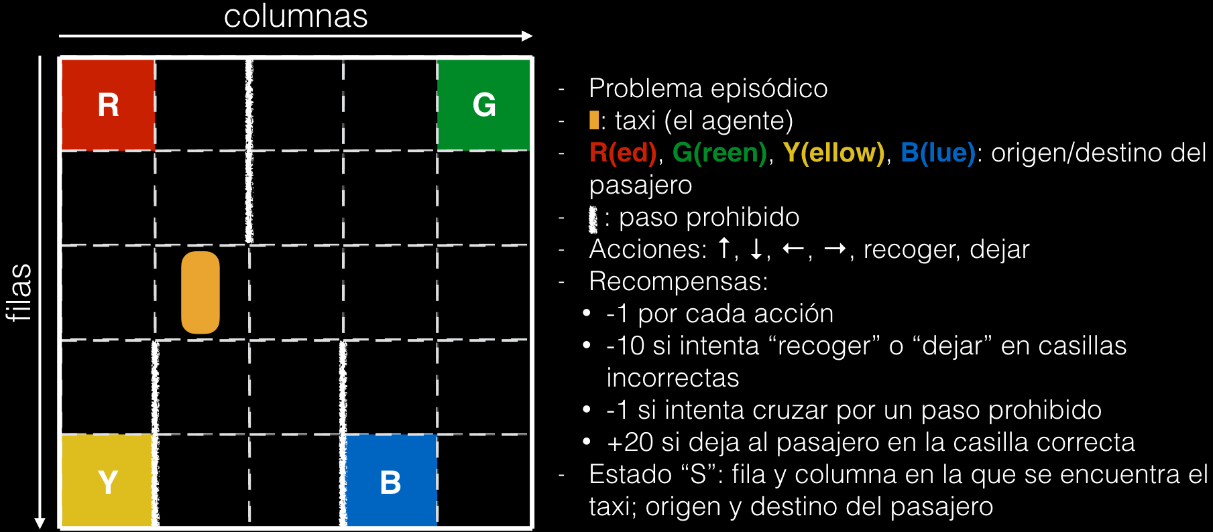

In [ ]:
# Se requiere la versión 0.23.1 de OpenAI Gym para poder
# usar el método "render". Versiones más recientes no
# funcionan con Google Colab
!pip install gym==0.23.1

In [ ]:
import gym

import numpy as np

import matplotlib.pyplot as plt


In [ ]:
# Crear el entorno y visualizar sus características
env = gym.make("Taxi-v3")
S = env.reset()
env.render()

print('Estado inicial: {}'.format(S))
print('Número de estados: {}'.format(env.observation_space.n))
print('Número de acciones: {}'.format(env.action_space.n))

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+

Estado inicial: 463
Número de estados: 500
Número de acciones: 6


In [ ]:
def mostrar_estado(env, S):
    '''Imprime en pantalla el estado actual (ubicación del taxi,
    destino y origen)

    Parámetros:
    - env: el entorno de OpenAI Gym
    - S: el estado actual codificado
    '''

    # Decodificar el estado
    tx_fil, tx_col, origen, destino = env.env.decode(S)

    # Diccionarios
    origenes = {0: 'R(ed)', 1: 'G(reen)', 2: 'Y(ellow)', 3: 'B(lue)', 4:'In taxi'}
    destinos = {0: 'R(ed)', 1: 'G(reen)', 2: 'Y(ellow)', 3: 'B(lue)'}

    # Imprimir información en pantalla
    print(f'Ubicación del taxi (fil, col): {tx_fil+1, tx_col+1}')
    print(f'Origen: {origenes[origen]}')
    print(f'Destino: {destinos[destino]}')

# -----------------------------------------------------
def inicializar_Q(nS, nA, tipo='ones'):
    '''
    Inicializar la función Q(S,A) a valores iguales a 1.

    Parámetros:
    - nS: número de estados
    - nA: número de acciones

    Retorna la matriz Q(S,A)
    '''
    if tipo == 'ones':
    	Q = np.ones((nS,nA))
    elif tipo == 'random':
    	Q = np.random.rand(nS,nA)

    return Q

# -----------------------------------------------------
def e_greedy(s, Q, e, nA):
    '''
    Para un estado "s" selecciona una acción proveniente de Q(S,A) usando el enfoque e-greedy

    Parámetros:
    - s: el estado para el cual se desea obtener la acción
    - Q(S,A): tabla Q con S estados y A acciones
    - e: valor de épsilon (entre 0 y 1)
    - nA: número de acciones

    Retorna la acción seleccionada
    '''

    if np.random.rand() >= e:
        # Tomar la mejor acción con una probabilidad 1-e
        accion = np.argmax(Q[s, :])
    else:
        # Tomar cualquier acción aleatoriamente (con probabilidad e)
        accion = np.random.randint(0, nA)

    return accion

# -----------------------------------------------------

In [ ]:
# El estado se encuentra codificado, así que usaremos
# la función "mostrar_estado" para decodificarlo e
# imprimir la información en pantalla
mostrar_estado(env, S)

Ubicación del taxi (fil, col): (5, 4)
Origen: R(ed)
Destino: B(lue)


In [ ]:
# Interacción
acciones = {0: 'abajo', 1: 'arriba', 2: 'derecha',
            3: 'izquierda', 4: 'recoger', 5: 'dejar'}

A = env.action_space.sample()
S, R, done, info = env.step(A)
env.render()

print(f'Acción seleccionada: {acciones[A]}')
mostrar_estado(env,S)
print(f'Recompensa obtenida: {R}')
print(f'¿Terminó el episodio?: {done}')

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)
Acción seleccionada: derecha
Ubicación del taxi (fil, col): (5, 5)
Origen: R(ed)
Destino: B(lue)
Recompensa obtenida: -1
¿Terminó el episodio?: False


Antes de ver la implementación, veamos dos de las funciones auxiliares:
- `inicializar_Q` que permite inicializar la tabla Q (función acción-valor)
- `e_greedy` que permite seleccionar una acción de la tabla Q usando un enfoque $\epsilon$-greedy

In [ ]:
# Prueba de la función "inicializar_Q"
Q = inicializar_Q(6,3, tipo='ones')
print(Q.shape)
print(Q)

Q = inicializar_Q(6,3, tipo='random')
print(Q.shape)
print(Q)

(6, 3)
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
(6, 3)
[[0.38910365 0.06050453 0.07051058]
 [0.19849086 0.59253953 0.69918275]
 [0.08990265 0.04407593 0.51883402]
 [0.99139476 0.93265676 0.04942441]
 [0.48799369 0.35575664 0.39933282]
 [0.13643716 0.45055813 0.56285074]]


En realidad, no interesa el tipo de inicialización a usar, pues tarde o temprano tanto SARSA como Q-learning llegarán a la función Q (y política) óptima.

Con el fin de comparar los dos algoritmos realizamos la inicialización tipo `ones`.

Veamos ahora la función `e_greedy`:

In [ ]:
# Prueba para el estado s=5
s = 5
e = 0.2 # La mejor acción tendrá una prob. de 1-e de ser seleccionada
a = e_greedy(s,Q,e,3) #Estados, posibles acciones...
print(f'Tabla Q para s={s}: {Q[s,:]}')
print(f'Acción seleccionada para e={e}: {a}')

Tabla Q para s=5: [0.13643716 0.45055813 0.56285074]
Acción seleccionada para e=0.2: 2


##Predicción


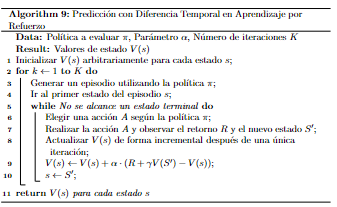

##Control

###Conceptos generales:

Se utiliza la función acción-vaor $Q_\pi(s, a)$ para encontrar una política óptima.

Se busca una combinación entre **Explotación y Exploración**


*   **Explotación:**

Tomamos la acción que maximiza la función:

$ \pi(a|s) = \arg\max_a Q_\pi(s, a)$

Desventaja: Al generar un número finito de escenarios, no podemos garantizar que se visiten todas las acciones posibles. De esta manera, la maximización de esta función no necesariamente es la mejor posible.


*   **Exploración:**

Escoger una acción de manera aleatoria y comenzar a mejorar iterativamente

---------------------------------------------------------------------------
De esta manera surgen los algoritmos codiciosos o *$ \epsilon$ greedy* para balancear explotación y exploración.

Estimar la función acción-valor (Q), y para cada par estado-acción, escoger la acción más adecuada.

*$ \epsilon$ greedy* Indicará la probabilidad de tomar ó el máximo valor de la función para ese estado en particular, o bien abrir la posibilidad a que se tomen cualquiera de las demás acciones disponibles.

---------------------------------------------------------------------------
**Tipos de control:**

*   on-policy:

Utilizamos la misma política que estamos optimizando para definir las acciones del agente

*   off-policy

Se utilizan dos políticas diferentes: una define el comportamiento del agente (cómo va a interactuar el agente con el entorno) y otra para optimizar iterativamente



###SARSA (on-policy)




El algoritmo SARSA actualiza el valor de Q para mejorar la política en función de la experiencia.

$
Q(s, a) \leftarrow Q(s, a) + \alpha \cdot [R + \gamma \cdot Q(s', a') - Q(s, a)]
$

Donde:
- \($Q(s, a$)\) es el valor del estado-acción.
- \($\alpha$) es la tasa de aprendizaje.
- \($R$) es la recompensa.
- \($\gamma$) es el factor de descuento.
- \($s'$) es el nuevo estado.
- \($a'$) es la nueva acción.

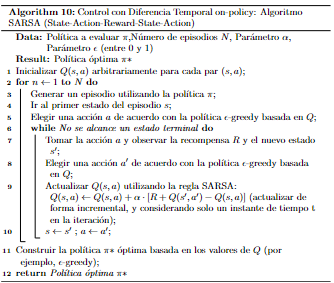

In [ ]:
# -----------------------------------------------------
def sarsa(env, alpha, gamma, epsilon, nS, nA, K, verbose=False):
    '''
    Algoritmo de control SARSA

    Parámetros:
    - env: el entorno
    - alpha: la tasa de aprendizaje (entre 0 y 1)
    - gamma: factor de descuento (entre 0 y 1)
    - epsilon: parámetro para el algoritmo e-greedy (entre 0 y 1)
    - nS, nA: número de estados y de acciones
    - K: número de episodios a generar
    - verbose: imprimir en pantalla el progreso del entrenamiento (por defecto falso)
    '''

    # Inicializar Q(S,A) y almacenar retorno (la evolucion del entrenamiento)
    Q = inicializar_Q(nS, nA)
    retorno = []

    # Correr K episodios de interacción y estimar Q(S,A)
    for episodio in range(K):
        # Inicializar retorno acumulado
        retorno_acumulado = 0

        # Ir al primer estado del episodio
        s = env.reset()

        # Elegir acción usando e-greedy
        a = e_greedy(s, Q, epsilon, nA)

        done = False # Aún no estamos en un estado terminal

        while not done:
            # Iniciar interacciones y actualizar función Q
            s_, r_, done, info = env.step(a)
            a_ = e_greedy(s_, Q, epsilon, nA)
            retorno_acumulado += r_

            if not done:
                # Actualizar Q si no es un episodio terminal
                Q[s, a] += alpha * ( r_ + (gamma * Q[s_, a_] ) - Q[s, a] )
            else:
                # Si el episodio es terminal no se añade gamma * Q[S_, a_]
                # (porque Q[s_, a_] = 0 por ser estado terminal)
                Q[s, a] += alpha * ( r_ - Q[s, a] )
                retorno.append(retorno_acumulado)

            # Actualizar el estado y la acción
            s, a = s_, a_

            # Imprimir información cada 100 episodios
            if verbose:
                if episodio%100 == 0:
                    print(f'Episodio: {episodio+1}/{K}:')
                    print(f'\t\tRecompensa: {r_}')


    # Al finalizar tendremos la tabla Q, que implícitamente
    # contendrá la política
    return Q, retorno

# -----------------------------------------------------

Entrenemos el agente con el algoritmo SARSA. Para ello usaremos la función `sarsa`, definiendo inicialmente los **hiperparámetros** sin un criterio en particular:

In [ ]:
# Hiperparámetros
ALPHA = 0.4
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
K = 2000

# Número de estados/acciones
NS = env.observation_space.n
NA = env.action_space.n

Q_s, ret_s = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

Veamos cuál ha sido el progreso del entrenamiento. La idea es que al comienzo el retorno obtenido (`ret_s`) debe ser bajo (valores negativos) y a medida que progresa este valor debería ser más alto (es decir cercano a cero):

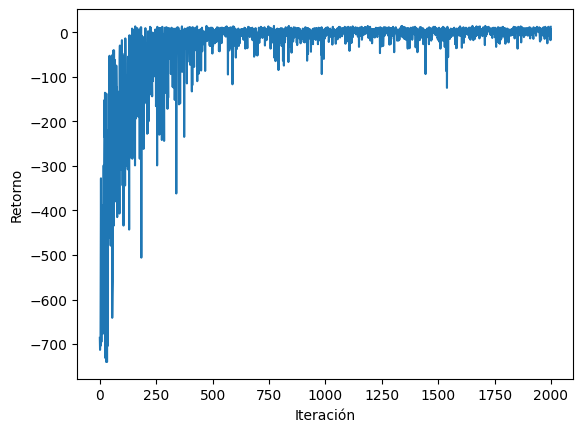

In [ ]:
plt.plot(ret_s)
plt.xlabel('Iteración');
plt.ylabel('Retorno');

Se cumple con lo mencionado anteriormente.

Pero ¿será que podemos mejorar este desempeño? La respuesta es sí, y para esto debemos realizar un **ajuste de los hiperparámetros**.

####Ajuste de Hiperparámetros

Este ajuste se debe hacer de forma sistemática, es decir modificando sólo uno de ellos, dejando los demás fijos, y observando si mejora/empeora el entrenamiento

In [ ]:
# -----------------------------------------------------
def graficar_entrenamiento(retornos, titulos):

    # Generar figura
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 6),
    	sharex=True, sharey=True)

    # Graficar
    ax1.plot(retornos[0])
    ax1.title.set_text(titulos[0])
    ax2.plot(retornos[1], 'tab:orange')
    ax2.title.set_text(titulos[1])
    ax3.plot(retornos[2], 'tab:green')
    ax3.title.set_text(titulos[2])
    ax4.plot(retornos[3], 'tab:red')
    ax4.title.set_text(titulos[3])

    # Etiquetar ejes
    plt.setp([ax3, ax4], xlabel='Iteración')
    plt.setp([ax1, ax3], ylabel='Retorno')
    # -----------------------------------------------------

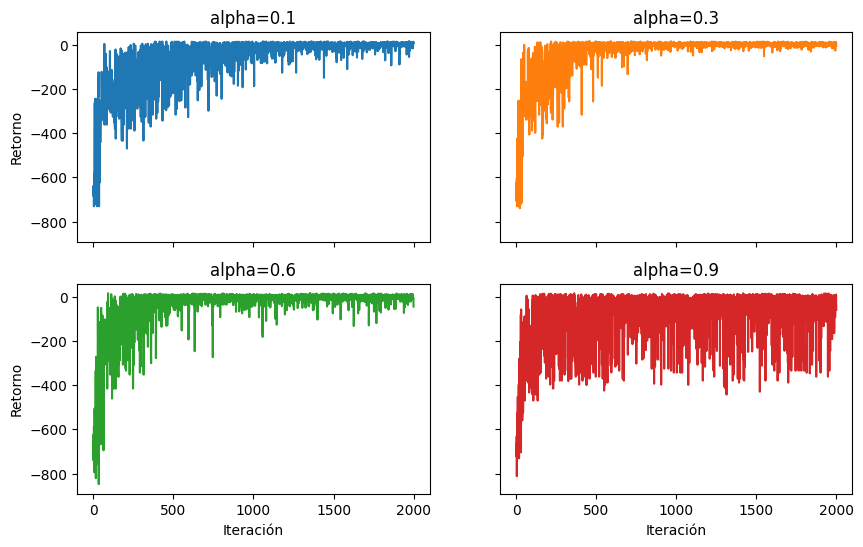

In [ ]:
# Entrenamiento con diferentes tasas de aprendizaje (ALPHA)
Q_s1, ret_s1 = sarsa(env, 0.1, GAMMA, EPSILON, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, 0.3, GAMMA, EPSILON, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, 0.6, GAMMA, EPSILON, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, 0.9, GAMMA, EPSILON, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['alpha=0.1', 'alpha=0.3', 'alpha=0.6', 'alpha=0.9']
graficar_entrenamiento(retornos, titulos)

Al parecer un ALPHA=0.3 resulta adecuado, porque con menos iteraciones logra estabilizarse (llegar casi a cero) más rápido el retorno obtenido.

Dejaremos fijo este hiperparámetro y nos enfocaremos ahora en K (el número de episodios usados en el entrenamiento):

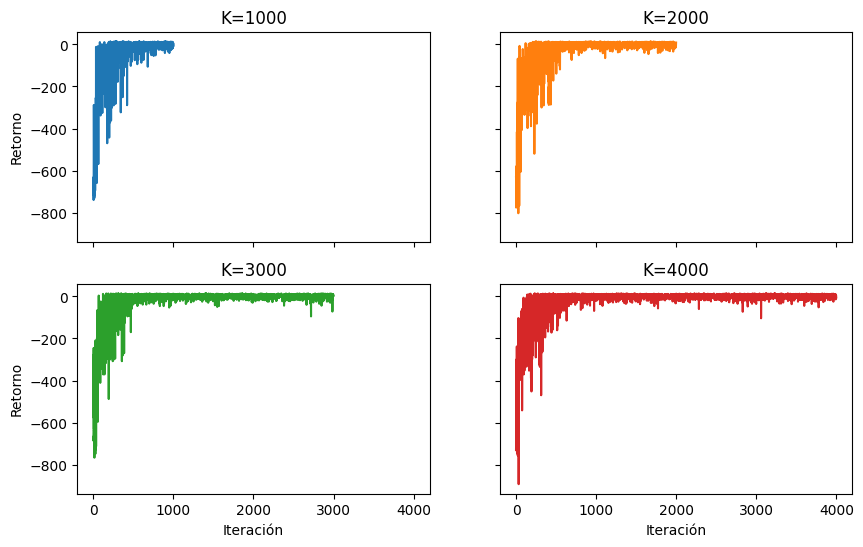

In [ ]:
# Entrenamiento con diferentes Ks
ALPHA = 0.35
Q_s1, ret_s1 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 1000)
Q_s2, ret_s2 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 2000)
Q_s3, ret_s3 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 3000)
Q_s4, ret_s4 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 4000)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['K=1000', 'K=2000', 'K=3000', 'K=4000']
graficar_entrenamiento(retornos, titulos)

No parece haber mucha diferencia entre uno y otro valor. Dado que el entrenamiento es relativamente rápido, usaremos K = 3000.

Ahora ajustaremos el hiperparámetro  ϵ :

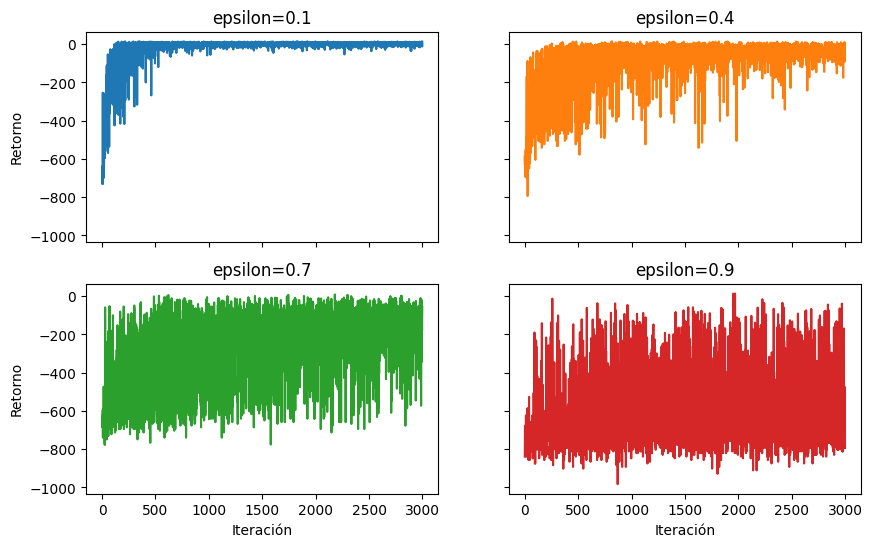

In [ ]:
K = 3000

# Entrenamiento con diferentes epsilon
Q_s1, ret_s1 = sarsa(env, ALPHA, GAMMA, 0.1, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, ALPHA, GAMMA, 0.4, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, ALPHA, GAMMA, 0.7, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, ALPHA, GAMMA, 0.9, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['epsilon=0.1', 'epsilon=0.4', 'epsilon=0.7', 'epsilon=0.9']
graficar_entrenamiento(retornos, titulos)

El resultado anterior tiene lógica, pues entre mayor sea  ϵ  mayor importancia estaremos dando a la exploración (es decir a acciones seleccionadas aleatoriamente) y menor a la explotación.

Así que ajustaremos  ϵ  en 0.1 y nos enfocaremos en el último hiperparámetro:  γ  (el factor de descuento):

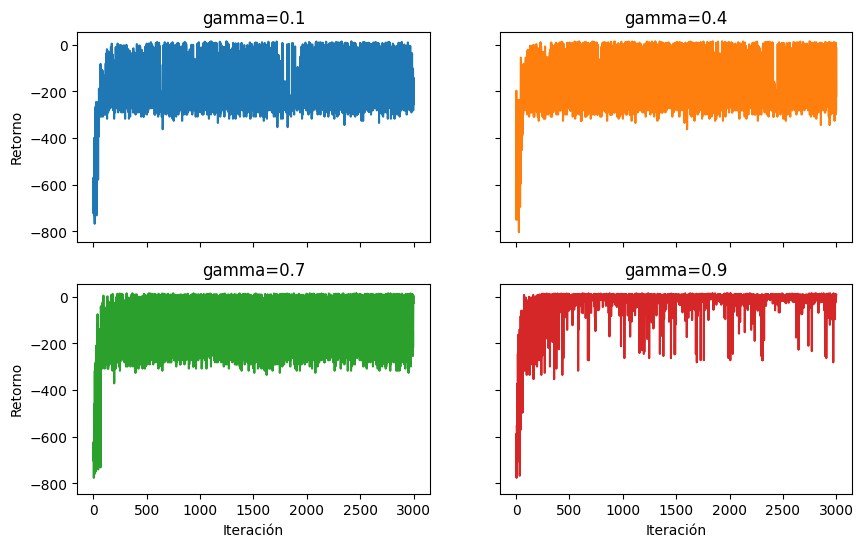

In [ ]:
EPSILON = 0.1

# Entrenamiento con diferentes gamma
Q_s1, ret_s1 = sarsa(env, ALPHA, 0.1, EPSILON, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, ALPHA, 0.4, EPSILON, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, ALPHA, 0.7, EPSILON, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, ALPHA, 0.9, EPSILON, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['gamma=0.1', 'gamma=0.4', 'gamma=0.7', 'gamma=0.9']
graficar_entrenamiento(retornos, titulos)

Observamos que entre más alto sea el valor de $\gamma$ más importancia le daremos al comportamiento futuro y menos a la acción presente y por tanto mejorará la interacción.

Así que usaremos un $\gamma$ lo más cercano posible a 1 (0.999) y entrenaremos el agente con los hiperparámetros ajustados:

- ALPHA = 0.3
- GAMMA = 0.999
- EPSILON = 0.1
- K = 4000

In [ ]:
GAMMA = 0.999

Q_s, ret_s = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

De esta manera, el agente ya está entrenado.

Al final de la práctica veremos cómo usar la tabla Q obtenida para generar interacciones. Pero antes veamos cómo realizar el entrenamiento con el algoritmo Q-learning.

###Q-Learning (off-policy")



El algoritmo Q-learning busca el valor óptimo de Q para encontrar la política óptima.

$
Q(s, a) \leftarrow Q(s, a) + \alpha \cdot [R + \gamma \cdot \max_a Q(s', a) - Q(s, a)]
$

Donde:
- \($Q(s, a$)\) es el valor del estado-acción.
- \($\alpha$) es la tasa de aprendizaje.
- \($R$) es la recompensa.
- \($\gamma$) es el factor de descuento.
- \($s'$) es el nuevo estado.
- \($a'$) es la nueva acción.
- \($max_a$) toma el valor óptimo para el siguiente estado.

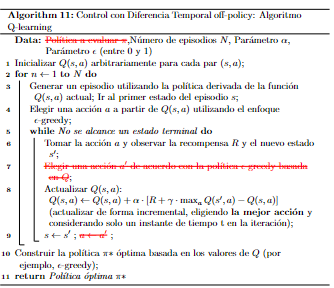

In [ ]:
# -----------------------------------------------------
def qlearning(env, alpha, gamma, epsilon, nS, nA, K, verbose=False):
    '''
    Algoritmo de control Q-learning

    Parámetros:
    - env: el entorno
    - alpha: la tasa de aprendizaje (entre 0 y 1)
    - gamma: factor de descuento (entre 0 y 1)
    - epsilon: parámetro para el algoritmo e-greedy
    - nS, nA: número de estados y de acciones
    - K: número de episodios a generar
    - verbose: imprimir en pantalla el progreso del entrenamiento (por defecto falso)
    '''

    # Inicializar Q(S,A) y almacenar retorno (la evolución del entrenamiento)
    Q = inicializar_Q(nS, nA)
    retorno = []

    # Correr K episodios de interacción y estimar Q(S,A)
    for episodio in range(K):
        # Inicializar retorno total
        retorno_acumulado = 0

        # Ir al primer estado del episodio
        s = env.reset()

        # Elegir acción usando e-greedy
        a = e_greedy(s, Q, epsilon, nA)

        done = False # Aún no estamos en un estado terminal

        while not done:
            # Iniciar interacciones y actualizar función Q
            s_, r_, done, info = env.step(a)
            a_ = np.argmax(Q[s_, :]) # <---- ESTA ES LA DIFERENCIA CON SARSA
            retorno_acumulado += r_

            if not done:
                # Si no es un episodio terminal, actualizar Q
                Q[s, a] += alpha * ( r_ + (gamma * Q[s_, a_] ) - Q[s, a] )
            else:
                # Si el episodio es terminal no se añade gamma * Q[S_, a_]
                # (porque Q[s_, a_] = 0 por ser estado terminal)
                Q[s, a] += alpha * ( r_ - Q[s, a] )
                retorno.append(retorno_acumulado)

            # Actualizar el estado y la acción
            s, a = s_, a_

            # Imprimir información cada 100 episodios
            if verbose:
                if episodio%100 == 0:
                    print(f'Episodio: {episodio+1}/{K}:')
                    print(f'\t\tRecompensa final: {r_}')


    # Al finalizar tendremos la tabla Q, que implícitamente
    # contendrá la política
    return Q, retorno

# -----------------------------------------------------

Seguiremos la misma lógica usada para el control con SARSA para llevar a cabo el entrenamiento de nuestro agente usando el algoritmo Q-learning.

En este caso usaremos la funcion `q_learning` que implementa este algoritmo:

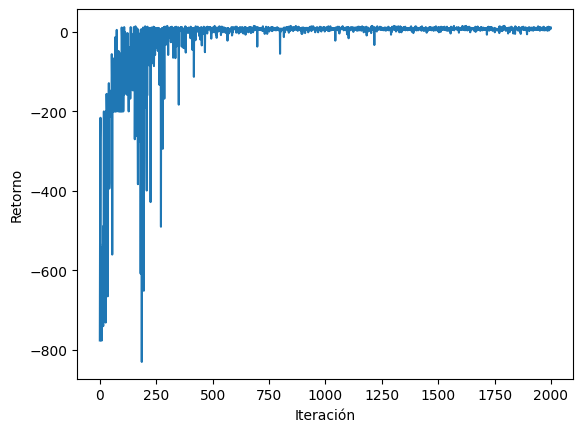

In [ ]:
# Prueba del algoritmo Q-learning usando un set arbitrario
# de hiperparámetros
ALPHA = 0.4
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
NS = env.observation_space.n
NA = env.action_space.n
K = 2000

Q_ql, ret_ql = qlearning(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

# Y grafiquemos la curva de entrenamiento
plt.plot(ret_ql)
plt.xlabel('Iteración');
plt.ylabel('Retorno');

####Ajuste de Hiperparámetros

De nuevo, al igual que con SARSA, en este caso debemos hacer un ajuste de hiperparámetros.

Así que, si seguimos el mismo procedimiento de antes, llegaremos a este set:

- ALPHA = 0.6
- GAMMA = 0.999
- EPSILON = 0.1
- K = 4000

Entrenemos nuestro agente con estos hiperparámetros:

In [ ]:
ALPHA = 0.6
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
K = 4000

Q_ql, ret_ql = qlearning(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

###Comparación



Ahora sí, con el agente entrenado usando los dos métodos, intentemos ver cuál de ellos tiene el mejor desempeño.

Para ello podemos simplemente graficar las curvas de entrenamiento obtenidas en cada caso:

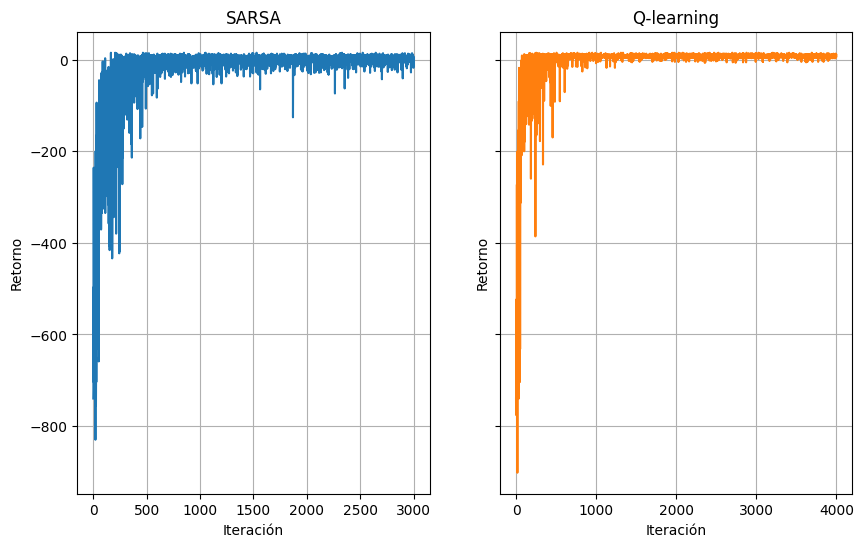

In [ ]:
fig, ((ax1, ax2)) = plt.subplots(1, 2, figsize=(10, 6), sharey=True)

# Graficar
ax1.plot(ret_s)
ax1.title.set_text('SARSA')
ax1.set_xlabel('Iteración')
ax1.grid(True)

ax2.plot(ret_ql, 'tab:orange')
ax2.title.set_text('Q-learning')
ax2.set_xlabel('Iteración')
ax2.grid(True)

plt.setp([ax1, ax2], ylabel='Retorno');

Vemos que la convergencia de Q-learning es significativamente más rápida que SARSA: en la iteración 1.000 (aprox.) ya se estabiliza el primero y su retorno ya es positivo, mientras que para esa misma iteración SARSA aún no se estabiliza (de hecho en la iteración 4.000 su retorno sigue siendo negativo en ocasiones).

Esto confirma que Q-learning permite entrenar el agente de forma adecuada y con un menor número de iteraciones en comparación con SARSA.

Ahora sí, hacemos que el agente interactúe con el entorno

##Interacción

In [ ]:
# -----------------------------------------------------
def interaccion(env, Q, method=None):
    it = 0
    s = env.reset()

    print('Resultado de la interacción:')
    print('-'*60)
    print('-'*60)

    # Imprimir estado y entorno iniciales
    print('**** Entorno-agente al inicio: ****')
    env.render()
    _, _, _, dest_i = env.env.decode(s)
    mostrar_estado(env, s)

    print('\nInteractuando...\n')

    # Hacer que el agente interactúe con el entorno tomando como política
    # el máximo de la función Q para cada estado
    a = np.argmax(Q[s,:]) # ¡La política!
    done = False

    # Interactuar hasta llegar a un estado terminal
    while not done:
        it += 1
        # Iniciar interacciones y actualizar función Q
        s, r, done, info = env.step(a)
        a = np.argmax(Q[s, :])

    # Imprimir información final
    _, _, _, dest_f = env.env.decode(s)
    if dest_i == dest_f:
        print(f'\nEl episodio culminó ***EXITOSAMENTE*** en {it} iteraciones')
    else:
        print(f'\nEl episodio culminó en {it} iteraciones')

    print('**** Entorno-agente al final: ****')
    env.render()
    mostrar_estado(env, s)
    print(f'Recompensa obtenida: {r}')

# -----------------------------------------------------

In [ ]:
#interaccion(env,Q_ql)
interaccion(env,Q_s)

Resultado de la interacción:
------------------------------------------------------------
------------------------------------------------------------
**** Entorno-agente al inicio: ****
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+

Ubicación del taxi (fil, col): (2, 1)
Origen: Y(ellow)
Destino: B(lue)

Interactuando...


El episodio culminó ***EXITOSAMENTE*** en 12 iteraciones
**** Entorno-agente al final: ****
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)
Ubicación del taxi (fil, col): (5, 4)
Origen: B(lue)
Destino: B(lue)
Recompensa obtenida: 20


# **Trabajo Práctico**

**PARTE 3: DIFERENCIA TEMPORAL: SARSA Y Q-LEARNING (Unidad 3)**

A partir del Google Colab suministrado UGR_AR_3_DiferenciaTemporalOpenAIGym_TA1
generar el código para:

* Ajustar los hiperparámetros de los algoritmos SARSA y Q-Learning evaluando:
○ ALPHA: 0.1, 0.2, 0.3 y 0.4
○ GAMMA: 0.99, 0.95, 0.90 y 0.85
○ EPSILON: 0.05, 0.1, 0.15 y 0.2
○ K: 100, 1000, 5000, 10000 (Considerar la variable costo computacional)

* Iterar al menos 1000 veces la interacción del agente con el entorno con cada uno de
los algoritmos

*  Para cada uno, guardar el resultado del timestep (cuántas acciones le toma llegar a
un estado terminal en cada iteración).

* Para cada uno, elaborar un indicador del porcentaje de éxito (cuántas veces llega el
agente a la meta sobre la cantidad de veces que lo intentó) y de la cantidad de
timestep promedio para todas las iteraciones (mostrar este resultado en un gráfico o
tabla).

* Indicar cuál de los dos algoritmos presenta mejores resultados. Justificar gráfica y
analíticamente.

**ENTREGABLES:**

1. Google Colab con la memoria del trabajo realizado (código + descripción/comentarios)

Nota: Los archivos se deben nombrar cómo: AAAANC_UGR_AR_TP2_ApellidoNombre
AAAA = AÑO
N = CUATRIMESTRE {1,2}


##  Diferencia Temporal: SARSA y Q-Learning

En esta parte del trabajo se evaluarán los algoritmos SARSA y Q-Learning en el entorno Taxi-v3 de OpenAI Gym.

Se analizará el efecto de los hiperparámetros ALPHA, GAMMA, EPSILON y K sobre el aprendizaje del agente. Para comparar los algoritmos se registrará la cantidad de acciones o timesteps de cada episodio, el porcentaje de éxito y el promedio de timesteps.

Finalmente, se compararán los resultados obtenidos para determinar qué algoritmo presenta un mejor desempeño en las pruebas realizadas.

**1. Código para medir cada episodio**

Esta celda reutiliza el entorno env de Taxi-v3 y registra los timesteps y los éxitos que necesitamos para el TP.

**Aclaración sobre los timesteps por episodio**

Para limitar la duración de cada episodio, se estableció un máximo de 200 acciones. Si el agente no alcanza el estado terminal dentro de ese límite, el episodio se registra con 200 timesteps y se contabiliza como no exitoso. De esta manera, se evita que un episodio se prolongue indefinidamente y se mantiene un límite uniforme para las pruebas de ambos algoritmos.

In [ ]:

import pandas as pd

# Elegir una acción con la política epsilon-greedy

def elegir_accion(estado, Q, epsilon, nA):
    return e_greedy(estado, Q, epsilon, nA)



# Entrenar SARSA o Q-Learning y registrar los resultados
def entrenar_y_medir(env, algoritmo, alpha, gamma, epsilon, K,
                     max_steps=200):

    nS = env.observation_space.n
    nA = env.action_space.n
    Q = inicializar_Q(nS, nA)
    registros = []

    for episodio in range(K):
        estado = env.reset()
        accion = elegir_accion(estado, Q, epsilon, nA)

        terminado = False
        pasos = 0
        recompensa_final = 0

        while not terminado and pasos < max_steps:
            siguiente_estado, recompensa, done, info = env.step(accion)
            pasos += 1
            recompensa_final = recompensa

            # Se limita la duración del episodio a max_steps
            fin = done or pasos >= max_steps

            if algoritmo == "SARSA":
                if not fin:
                    siguiente_accion = elegir_accion(
                        siguiente_estado, Q, epsilon, nA
                    )
                    objetivo = recompensa + gamma * Q[
                        siguiente_estado, siguiente_accion
                    ]
                else:
                    objetivo = recompensa

                Q[estado, accion] += alpha * (
                    objetivo - Q[estado, accion]
                )

                if not fin:
                    estado = siguiente_estado
                    accion = siguiente_accion

            elif algoritmo == "Q-Learning":
                if fin:
                    objetivo = recompensa
                else:
                    objetivo = recompensa + gamma * np.max(
                        Q[siguiente_estado, :]
                    )

                Q[estado, accion] += alpha * (
                    objetivo - Q[estado, accion]
                )

                if not fin:
                    estado = siguiente_estado
                    accion = elegir_accion(
                        estado, Q, epsilon, nA
                    )
            else:
                raise ValueError("Algoritmo no reconocido")

            terminado = fin

        registros.append({
            "episodio": episodio + 1,
            "timesteps": pasos,
            "recompensa_final": recompensa_final,
            "exito": recompensa_final == 20
        })

    return Q, pd.DataFrame(registros)


* timesteps: cuenta las acciones ejecutadas durante cada episodio.



* exito: considera exitoso el episodio cuando el agente recibe la recompensa de 20, correspondiente a completar correctamente el objetivo en Taxi-v3.



* SARSA: actualiza la tabla Q utilizando la acción siguiente elegida por la política.



* Q-Learning: utiliza el mayor valor Q disponible para el siguiente estado.



* max_steps=200: evita que un episodio quede ejecutándose indefinidamente.

**2. Función para calcular los indicadores**

Esta funcion calcula el porcentaje de éxito y el promedio de timesteps, que son dos resultados centrales de la consigna.

In [ ]:

def resumir_resultados(datos):
    intentos = len(datos)
    exitos = datos["exito"].sum()

    porcentaje_exito = 100 * exitos / intentos
    promedio_timesteps = datos["timesteps"].mean()

    return {
        "intentos": intentos,
        "exitos": int(exitos),
        "porcentaje_exito": round(porcentaje_exito, 2),
        "promedio_timesteps": round(promedio_timesteps, 2)
    }


Por ejemplo, si en 1.000 episodios el agente llega a la meta 800 veces, su porcentaje de éxito será del 80 %. El promedio de timesteps se calcula con los episodios realizados, no solamente con los exitosos.

**3. Evaluar los cuatro hiperparámetros**

Se analizarán los valores indicados en la consigna para cada algoritmo. Para estudiar el efecto de cada hiperparámetro se modificarán sus valores manteniendo constantes los restantes. En las pruebas de ALPHA, GAMMA y EPSILON se utilizarán 1.000 episodios por configuración. Para K se evaluarán las cantidades 100, 1.000, 5.000 y 10.000 episodios, considerando también el costo computacional.

In [ ]:

# Valores solicitados en la consigna
valores_alpha = [0.1, 0.2, 0.3, 0.4]
valores_gamma = [0.99, 0.95, 0.90, 0.85]
valores_epsilon = [0.05, 0.1, 0.15, 0.2]
valores_K = [100, 1000, 5000, 10000]

# Configuración de referencia
base = {
    "alpha": 0.3,
    "gamma": 0.99,
    "epsilon": 0.1,
    "K": 1000
}

# Listas para guardar los resultados
resultados_pruebas = []
registros_timesteps = []

def probar_parametro(algoritmo, nombre, valores):
    resultados = []

    for valor in valores:
        config = base.copy()
        config[nombre] = valor

        Q, datos = entrenar_y_medir(
            env,
            algoritmo,
            config["alpha"],
            config["gamma"],
            config["epsilon"],
            config["K"]
        )

        resumen = resumir_resultados(datos)
        resumen["algoritmo"] = algoritmo
        resumen["parametro"] = nombre.upper()
        resumen["valor"] = valor
        resultados.append(resumen)

        # Guardar cada episodio de esta configuración
        for _, fila in datos.iterrows():
            registros_timesteps.append({
                "algoritmo": algoritmo,
                "parametro": nombre.upper(),
                "valor": valor,
                "episodio": int(fila["episodio"]),
                "timesteps": int(fila["timesteps"]),
                "exito": bool(fila["exito"]),
                "recompensa_final": fila["recompensa_final"],
                "alpha": config["alpha"],
                "gamma": config["gamma"],
                "epsilon": config["epsilon"],
                "K": config["K"]
            })

        print(
            algoritmo, nombre, "=", valor,
            "| Éxito:", resumen["porcentaje_exito"], "%",
            "| Timesteps promedio:",
            resumen["promedio_timesteps"]
        )

    return pd.DataFrame(resultados)


# Evaluar los parámetros en ambos algoritmos
for algoritmo in ["SARSA", "Q-Learning"]:
    for nombre, valores in [
        ("alpha", valores_alpha),
        ("gamma", valores_gamma),
        ("epsilon", valores_epsilon),
        ("K", valores_K)
    ]:
        tabla = probar_parametro(algoritmo, nombre, valores)
        resultados_pruebas.append(tabla)

# Tabla resumen de todas las configuraciones
tabla_hiperparametros = pd.concat(
    resultados_pruebas, ignore_index=True
)

display(tabla_hiperparametros)

# Tabla con los timesteps de cada episodio
tabla_timesteps = pd.DataFrame(registros_timesteps)

print("Cantidad de registros individuales:", len(tabla_timesteps))
display(tabla_timesteps.head(10))



SARSA alpha = 0.1 | Éxito: 80.9 % | Timesteps promedio: 91.43
SARSA alpha = 0.2 | Éxito: 88.1 % | Timesteps promedio: 60.83
SARSA alpha = 0.3 | Éxito: 91.1 % | Timesteps promedio: 52.12
SARSA alpha = 0.4 | Éxito: 91.1 % | Timesteps promedio: 46.28
SARSA gamma = 0.99 | Éxito: 90.2 % | Timesteps promedio: 50.81
SARSA gamma = 0.95 | Éxito: 89.3 % | Timesteps promedio: 54.53
SARSA gamma = 0.9 | Éxito: 88.7 % | Timesteps promedio: 59.41
SARSA gamma = 0.85 | Éxito: 82.6 % | Timesteps promedio: 69.57
SARSA epsilon = 0.05 | Éxito: 91.4 % | Timesteps promedio: 48.1
SARSA epsilon = 0.1 | Éxito: 90.1 % | Timesteps promedio: 51.2
SARSA epsilon = 0.15 | Éxito: 87.6 % | Timesteps promedio: 60.94
SARSA epsilon = 0.2 | Éxito: 88.5 % | Timesteps promedio: 61.46
SARSA K = 100 | Éxito: 24.0 % | Timesteps promedio: 176.16
SARSA K = 1000 | Éxito: 89.0 % | Timesteps promedio: 54.27
SARSA K = 5000 | Éxito: 97.74 % | Timesteps promedio: 23.27
SARSA K = 10000 | Éxito: 99.08 % | Timesteps promedio: 19.47
Q-Lear

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,intentos,exitos,porcentaje_exito,promedio_timesteps,algoritmo,parametro,valor
0,1000,809,80.90,91.43,SARSA,ALPHA,0.10
1,1000,881,88.10,60.83,SARSA,ALPHA,0.20
2,1000,911,91.10,52.12,SARSA,ALPHA,0.30
3,1000,911,91.10,46.28,SARSA,ALPHA,0.40
4,1000,902,90.20,50.81,SARSA,GAMMA,0.99
5,1000,893,89.30,54.53,SARSA,GAMMA,0.95
6,1000,887,88.70,59.41,SARSA,GAMMA,0.90
7,1000,826,82.60,69.57,SARSA,GAMMA,0.85
8,1000,914,91.40,48.10,SARSA,EPSILON,0.05
9,1000,901,90.10,51.20,SARSA,EPSILON,0.10


Cantidad de registros individuales: 56200


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algoritmo,parametro,valor,episodio,timesteps,exito,recompensa_final,alpha,gamma,epsilon,K
0,SARSA,ALPHA,0.1,1,200,False,-1,0.1,0.99,0.1,1000
1,SARSA,ALPHA,0.1,2,200,False,-1,0.1,0.99,0.1,1000
2,SARSA,ALPHA,0.1,3,200,False,-1,0.1,0.99,0.1,1000
3,SARSA,ALPHA,0.1,4,200,False,-1,0.1,0.99,0.1,1000
4,SARSA,ALPHA,0.1,5,200,False,-10,0.1,0.99,0.1,1000
5,SARSA,ALPHA,0.1,6,200,False,-1,0.1,0.99,0.1,1000
6,SARSA,ALPHA,0.1,7,200,False,-1,0.1,0.99,0.1,1000
7,SARSA,ALPHA,0.1,8,200,False,-1,0.1,0.99,0.1,1000
8,SARSA,ALPHA,0.1,9,200,False,-1,0.1,0.99,0.1,1000
9,SARSA,ALPHA,0.1,10,200,False,-1,0.1,0.99,0.1,1000


**Importante:** esta parte ejecuta bastantes episodios, sobre todo cuando K=10000. Puede tardar unos minutos. Si se interrumpe por tiempo o memoria, avisame y lo organizamos en bloques más pequeños, sin eliminar los valores exigidos por la consigna.

**4. Análisis de grafico de los hiperparámetros**



Se utilizarán gráficos para comparar el porcentaje de éxito y el promedio de timesteps obtenido con los distintos valores de cada hiperparámetro. Estos gráficos permitirán observar qué configuraciones ofrecen mejores resultados y cómo influyen los parámetros en el aprendizaje.

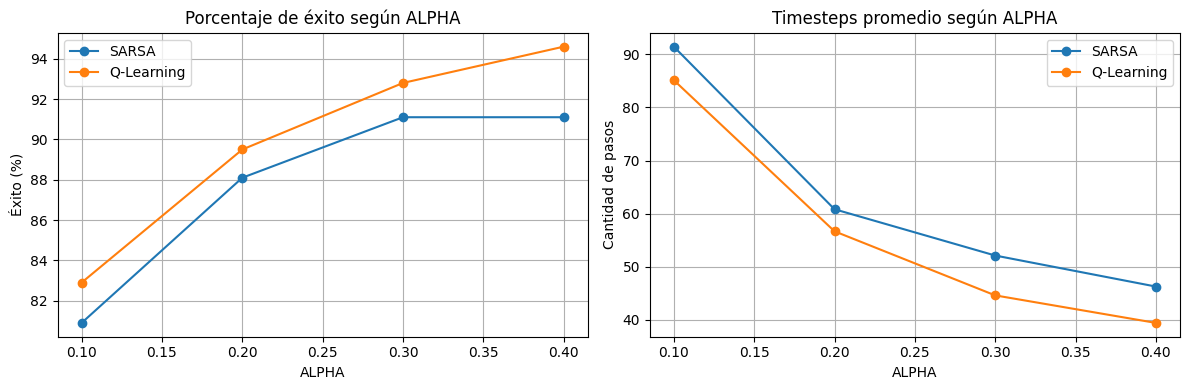

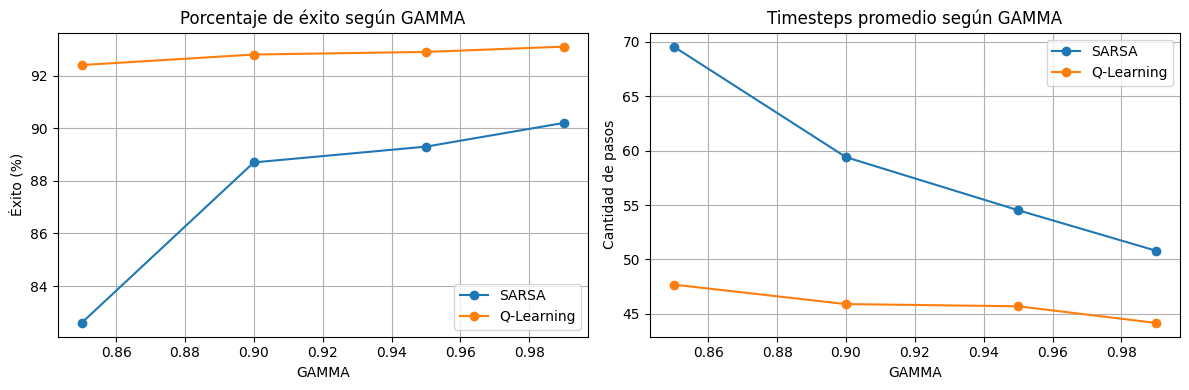

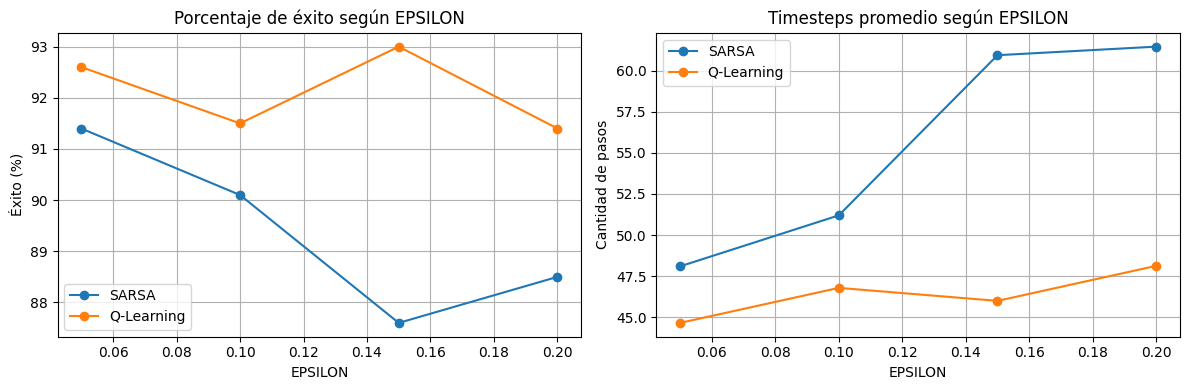

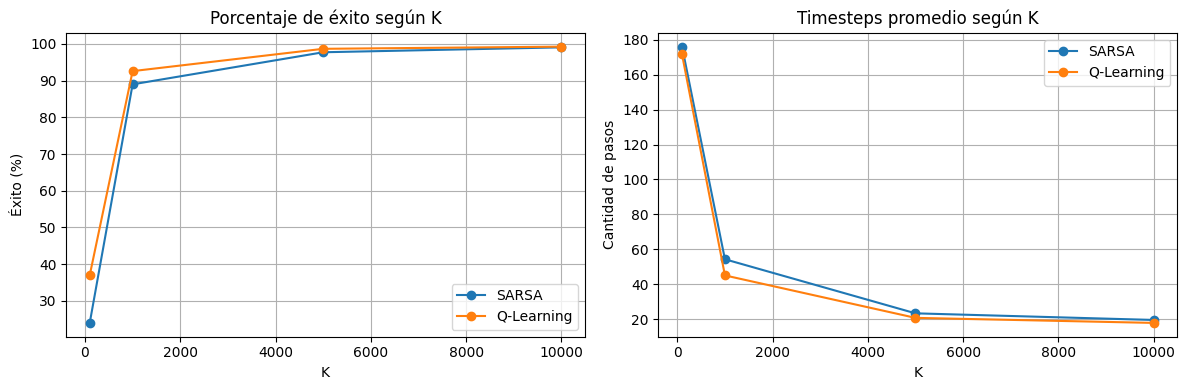

In [ ]:

# Un gráfico para cada hiperparámetro
for parametro in ["ALPHA", "GAMMA", "EPSILON", "K"]:

    subset = tabla_hiperparametros[
        tabla_hiperparametros["parametro"] == parametro
    ]

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    for algoritmo in ["SARSA", "Q-Learning"]:
        datos_algoritmo = subset[
            subset["algoritmo"] == algoritmo
        ].sort_values("valor")

        ejes[0].plot(
            datos_algoritmo["valor"],
            datos_algoritmo["porcentaje_exito"],
            marker="o",
            label=algoritmo
        )

        ejes[1].plot(
            datos_algoritmo["valor"],
            datos_algoritmo["promedio_timesteps"],
            marker="o",
            label=algoritmo
        )

    ejes[0].set_title(f"Porcentaje de éxito según {parametro}")
    ejes[0].set_xlabel(parametro)
    ejes[0].set_ylabel("Éxito (%)")
    ejes[0].legend()
    ejes[0].grid(True)

    ejes[1].set_title(f"Timesteps promedio según {parametro}")
    ejes[1].set_xlabel(parametro)
    ejes[1].set_ylabel("Cantidad de pasos")
    ejes[1].legend()
    ejes[1].grid(True)

    plt.tight_layout()
    plt.show()


**5. Comparación final entre SARSA y Q-Learning**

Una vez analizados los hiperparámetros, se realizará una comparación final entre SARSA y Q-Learning. Se utilizará la misma cantidad de episodios para ambos algoritmos y se calcularán el porcentaje de éxito y el promedio de timesteps. Los resultados se presentarán mediante una tabla y un gráfico comparativo.

,algoritmo,intentos,exitos,porcentaje_exito,promedio_timesteps
0,SARSA,1000,899,89.9,52.96
1,Q-Learning,1000,929,92.9,44.42


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


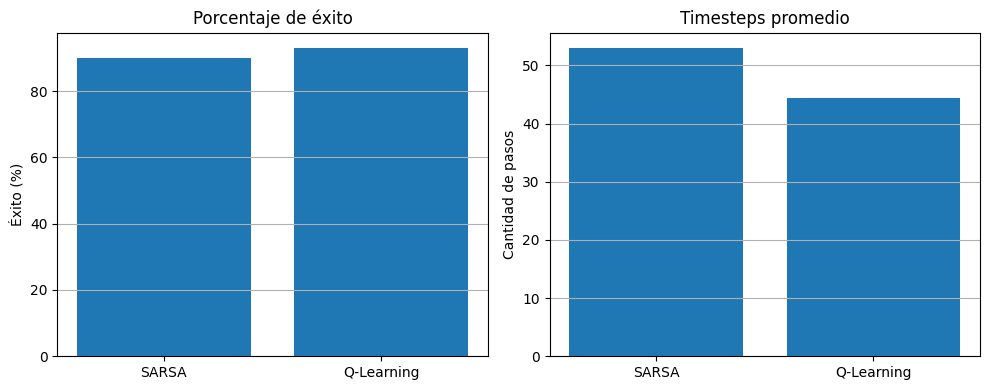

In [ ]:

# Configuración inicial de la comparación final.
# Después de analizar los gráficos, podemos ajustar estos valores.
ALPHA_FINAL = 0.3
GAMMA_FINAL = 0.99
EPSILON_FINAL = 0.1
K_FINAL = 1000

# Entrenar ambos algoritmos con la misma cantidad de episodios
Q_sarsa_final, datos_sarsa = entrenar_y_medir(
    env, "SARSA",
    ALPHA_FINAL, GAMMA_FINAL, EPSILON_FINAL, K_FINAL
)

Q_ql_final, datos_ql = entrenar_y_medir(
    env, "Q-Learning",
    ALPHA_FINAL, GAMMA_FINAL, EPSILON_FINAL, K_FINAL
)

# Resumir resultados
resumen_sarsa = resumir_resultados(datos_sarsa)
resumen_ql = resumir_resultados(datos_ql)

comparacion = pd.DataFrame([
    {"algoritmo": "SARSA", **resumen_sarsa},
    {"algoritmo": "Q-Learning", **resumen_ql}
])

display(comparacion)

# Gráficos comparativos
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

ejes[0].bar(
    comparacion["algoritmo"],
    comparacion["porcentaje_exito"]
)
ejes[0].set_title("Porcentaje de éxito")
ejes[0].set_ylabel("Éxito (%)")
ejes[0].grid(axis="y")

ejes[1].bar(
    comparacion["algoritmo"],
    comparacion["promedio_timesteps"]
)
ejes[1].set_title("Timesteps promedio")
ejes[1].set_ylabel("Cantidad de pasos")
ejes[1].grid(axis="y")

plt.tight_layout()
plt.show()


ÇConclusiones

Se evaluaron los algoritmos SARSA y Q-Learning en el entorno Taxi-v3, utilizando distintos valores de ALPHA, GAMMA, EPSILON y K. Se registraron los timesteps de cada episodio y se calcularon el porcentaje de éxito y la cantidad promedio de pasos.

En la comparación final, con 1.000 episodios para cada algoritmo, SARSA alcanzó un porcentaje de éxito del 89,9 % y un promedio de 52,96 timesteps. Q-Learning obtuvo un porcentaje de éxito del 92,9 % y un promedio de 44,42 timesteps.

En esta ejecución, Q-Learning presentó un mejor desempeño, ya que alcanzó la meta en una mayor proporción de intentos y necesitó menos pasos en promedio. Esta conclusión se fundamenta en los indicadores calculados y en los gráficos comparativos.

El análisis de los hiperparámetros permitió comparar distintas configuraciones y observar cómo varían los resultados según los valores utilizados. También se consideró el costo computacional asociado a entrenamientos con distinta cantidad de episodios.

Los resultados corresponden a las ejecuciones realizadas en este trabajo y no implican que un algoritmo sea siempre superior en cualquier entorno o configuración.